# 03 Clustering and cluster profiling

**Clustering** means grouping customers so that people in the same group are alike and people in different groups are not. There are no right answers to check against (no labels), so we judge the groups with *internal* measures that only use the data itself, plus a stability test.

We use **KMeans**: pick k centre points, assign each customer to the nearest centre, move each centre to the average of its customers, and repeat until nothing changes. We must choose k ourselves, which is what Step 7 is about.

## Step 7: Clustering and metrics

**What this cell does:** Loads the scaled table made in notebook 02.  
**What to look for:** 8,950 rows and 11 columns, no missing values.  
**What the output means:** This is the data every clustering method below uses. Because it was saved to disk, this notebook runs on its own.

In [1]:
# Imported here so this step only loads the libraries when it runs
from pathlib import Path
import numpy as np
import pandas as pd


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the current folder until we see pyproject.toml (nbconvert runs inside notebooks/)."""
    return next(folder for folder in [start, *start.parents] if (folder / "pyproject.toml").exists())


ROOT = find_project_root()
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

scaled = pd.read_csv(PROCESSED_DIR / "credit_card_scaled.csv", index_col=0)  # CUST_ID is the row label
print(f"{scaled.shape=}, {scaled.isna().sum().sum()=}")
RANDOM_STATE = 42  # fixed so the results can be repeated
K_VALUES = range(2, 11)

scaled.shape=(8950, 11), scaled.isna().sum().sum()=np.int64(0)


### The four measures

| Measure | What it asks | Better is |
|---|---|---|
| **Inertia** | How far, in total, are customers from their own cluster centre? (Always falls as k grows, so we look for the *elbow* where the gains slow down.) | lower, but only until the elbow |
| **Silhouette** (-1 to 1) | For each customer: am I closer to my own cluster than to the next nearest one? | higher |
| **Davies-Bouldin** | How much do clusters overlap relative to how spread out they are? | lower |
| **Calinski-Harabasz** | Ratio of the spread *between* clusters to the spread *inside* them. | higher |

**What this cell does:** Fits KMeans for every k from 2 to 10 and computes all four measures for each.  
**What to look for:** How each column changes with k. Note where silhouette peaks, where Davies-Bouldin is lowest and where Calinski-Harabasz peaks.  
**What the output means:** The measures often disagree. When they do, we weigh them together with how useful the segments are for the business, rather than trusting one number.

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

kmeans_rows = []
kmeans_labels = {}  # keep the labels for later use
for k in K_VALUES:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(scaled)  # n_init=10: try 10 starts, keep the best
    kmeans_labels[k] = model.labels_
    kmeans_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(scaled, model.labels_),
        "davies_bouldin": davies_bouldin_score(scaled, model.labels_),
        "calinski_harabasz": calinski_harabasz_score(scaled, model.labels_),
        "smallest_cluster_%": np.bincount(model.labels_).min() / len(scaled) * 100,  # guards against tiny clusters
    })
kmeans_table = pd.DataFrame(kmeans_rows).set_index("k")
kmeans_table.round(3)

,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_%
k,,,,,
2,78791.075,0.216,1.896,2232.602,39.095
3,65967.972,0.210,1.624,2202.714,26.212
4,58687.444,0.212,1.597,2020.400,15.162
5,53212.054,0.223,1.506,1901.157,6.905
6,48519.808,0.217,1.502,1840.798,6.648
7,45633.914,0.187,1.506,1725.088,6.603
8,43230.336,0.192,1.477,1631.711,2.726
9,40980.511,0.200,1.431,1567.319,2.726
10,39073.362,0.198,1.452,1509.490,2.715


**What this cell does:** Finds the elbow automatically with the kneed library and plots all four measures against k.  
**What to look for:** A bend in the inertia curve (the dashed line marks kneed's pick) and the peaks or dips in the other three panels.  
**What the output means:** kneed looks for the point where the curve bends most, meaning extra clusters stop paying off (the 'knee'). It is a helpful hint, not a verdict, because real elbows are often gentle.

knee.knee=np.int64(5)


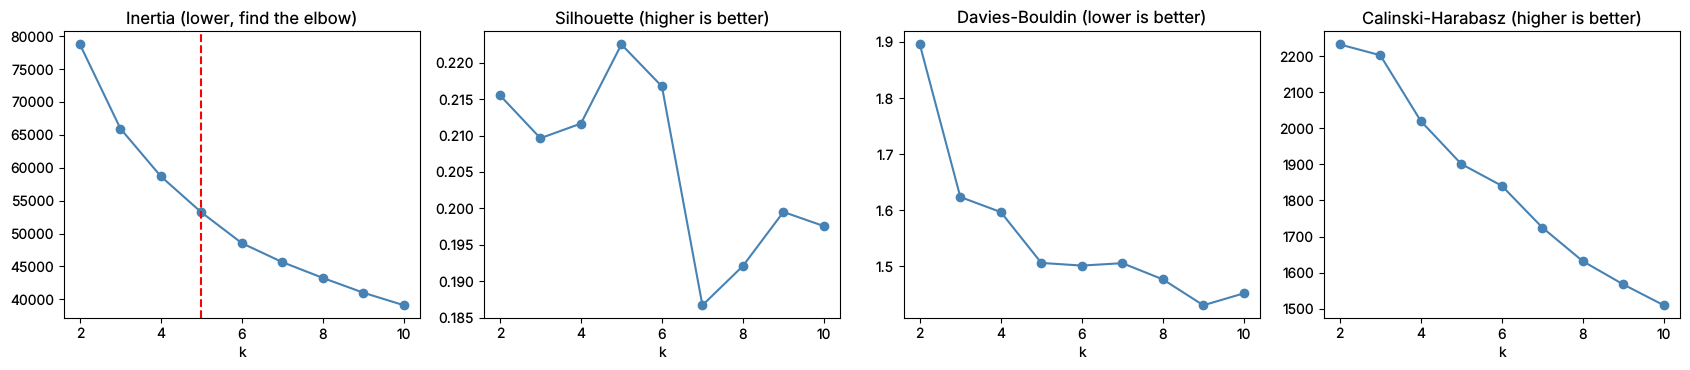

In [3]:
import matplotlib.pyplot as plt  # imported here because plotting starts in this cell
from kneed import KneeLocator   # automatic elbow finder

knee = KneeLocator(list(K_VALUES), kmeans_table["inertia"].tolist(), curve="convex", direction="decreasing")
print(f"{knee.knee=}")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
plots = [("inertia", "Inertia (lower, find the elbow)"), ("silhouette", "Silhouette (higher is better)"),
         ("davies_bouldin", "Davies-Bouldin (lower is better)"), ("calinski_harabasz", "Calinski-Harabasz (higher is better)")]
for axis, (column, title) in zip(axes, plots):
    axis.plot(kmeans_table.index, kmeans_table[column], marker="o", color="steelblue")
    axis.set(title=title, xlabel="k")
if knee.knee:
    axes[0].axvline(knee.knee, color="red", linestyle="--")  # kneed's elbow pick
fig.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_metrics.png", dpi=110)
plt.show()

### Stability: would we get the same groups on different customers?

Clusters that appear only for one particular sample are a fluke. To test this, we repeat the following 30 times for each k:

1. Draw a *bootstrap sample* (a random sample of 8,950 customers drawn **with replacement**, so some customers appear twice and others not at all).
2. Fit KMeans on that sample only.
3. Use that model to assign **all** 8,950 customers to a cluster.
4. Compare those labels with our reference labels (from the fit on all data) using the **Adjusted Rand Index (ARI)**.

ARI measures how much two ways of grouping the same customers agree. 1 means identical groupings, 0 means no better than random. Cluster *numbers* do not matter (cluster 2 in one run can be cluster 5 in another), only who is grouped with whom. Each bootstrap fit gets the same 10 random starts as the reference fit, so the comparison is fair (with fewer starts a fit can land on a worse solution and look unstable when it is not). We predict on the full data so both sets of labels cover the same customers. (Comparing the labels of two different bootstrap samples directly is a common mistake, because they contain different people.)

**What this cell does:** Runs the bootstrap stability test for every k and summarises the ARI scores.  
**What to look for:** A high mean ARI (above about 0.8 is solid, below 0.6 is shaky) and a small spread.  
**What the output means:** High stability means the same groups keep appearing when the customers change slightly, so they are not a fluke. A sharp drop at some k suggests the data does not really support that many groups.

In [4]:
from sklearn.metrics import adjusted_rand_score

N_BOOTSTRAPS = 30
random_generator = np.random.default_rng(RANDOM_STATE)  # the modern way to get repeatable randomness
stability_rows = []
for k in K_VALUES:
    reference_labels = kmeans_labels[k]  # labels from the fit on ALL customers
    scores = []
    for _ in range(N_BOOTSTRAPS):
        picked = random_generator.integers(0, len(scaled), size=len(scaled))   # row numbers drawn with replacement
        bootstrap_model = KMeans(n_clusters=k, n_init=10, random_state=int(random_generator.integers(1_000_000))).fit(scaled.iloc[picked])
        predicted_on_all = bootstrap_model.predict(scaled)                     # label every customer with this model
        scores.append(adjusted_rand_score(reference_labels, predicted_on_all)) # agreement with the reference
    stability_rows.append({"k": k, "mean_ARI": np.mean(scores), "std_ARI": np.std(scores), "min_ARI": np.min(scores)})
stability_table = pd.DataFrame(stability_rows).set_index("k")
stability_table.round(3)

,mean_ARI,std_ARI,min_ARI
k,,,
2,0.965,0.032,0.894
3,0.968,0.013,0.944
4,0.924,0.051,0.835
5,0.934,0.031,0.882
6,0.976,0.007,0.961
7,0.917,0.083,0.696
8,0.789,0.133,0.623
9,0.701,0.119,0.540
10,0.766,0.150,0.527


### A second method for comparison

- **Gaussian Mixture Model (GMM):** assumes the data is a mix of k bell-shaped clouds and gives each customer a probability for each cloud. It allows clusters of different sizes and shapes, while KMeans prefers round clusters of similar size.
- **Agglomerative clustering (Ward):** starts with every customer alone and repeatedly merges the two closest groups. Needs no random start.

We compare them with the same internal measures only. We have no true labels, so we do not use accuracy. GMM also reports **BIC** (Bayesian information criterion), a score that rewards a good fit but penalises extra parameters (lower is better).

**What this cell does:** Fits GMM and Agglomerative clustering for k from 2 to 10 and builds one comparison table with the same measures.  
**What to look for:** Whether either method beats KMeans at the same k on silhouette, Davies-Bouldin and Calinski-Harabasz.  
**What the output means:** If a different method gives a similar score, the structure is a property of the data, not of KMeans. If it is clearly better, we should think about switching.

In [5]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture

comparison_rows = []
gmm_bic = {}
gmm_labels = {}
agglomerative_labels = {}
for k in K_VALUES:
    gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=RANDOM_STATE).fit(scaled)
    gmm_labels[k] = gmm.predict(scaled)       # hard assignment: most likely cloud for each customer
    gmm_bic[k] = gmm.bic(scaled)
    agglomerative_labels[k] = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(scaled)
    for method, label_set in [("KMeans", kmeans_labels), ("GMM", gmm_labels), ("Agglomerative", agglomerative_labels)]:
        labels = label_set[k]
        comparison_rows.append({
            "method": method, "k": k,
            "silhouette": silhouette_score(scaled, labels),
            "davies_bouldin": davies_bouldin_score(scaled, labels),
            "calinski_harabasz": calinski_harabasz_score(scaled, labels),
            "smallest_cluster_%": np.bincount(labels).min() / len(labels) * 100,
        })
comparison_table = pd.DataFrame(comparison_rows)
# One-liner: pivot makes one row per k and one column per method for a chosen measure
display(comparison_table.pivot(index="k", columns="method", values="silhouette").round(3).rename_axis(columns="silhouette"))
display(comparison_table.pivot(index="k", columns="method", values="davies_bouldin").round(3).rename_axis(columns="davies_bouldin"))
display(comparison_table.pivot(index="k", columns="method", values="calinski_harabasz").round(0).rename_axis(columns="calinski_harabasz"))
print("GMM BIC by k (lower is better):")
print(pd.Series(gmm_bic).round(0).to_string())

silhouette,Agglomerative,GMM,KMeans
k,,,
2,0.151,0.144,0.216
3,0.160,0.142,0.210
4,0.164,0.147,0.212
5,0.188,0.148,0.223
6,0.197,0.140,0.217
7,0.175,0.116,0.187
8,0.149,0.087,0.192
9,0.142,0.119,0.200
10,0.150,0.084,0.198


davies_bouldin,Agglomerative,GMM,KMeans
k,,,
2,2.346,2.674,1.896
3,1.999,2.215,1.624
4,1.789,2.672,1.597
5,1.626,3.475,1.506
6,1.545,2.849,1.502
7,1.559,2.718,1.506
8,1.599,2.575,1.477
9,1.591,2.220,1.431
10,1.612,2.827,1.452


calinski_harabasz,Agglomerative,GMM,KMeans
k,,,
2,1428.0,1163.0,2233.0
3,1538.0,1355.0,2203.0
4,1532.0,1166.0,2020.0
5,1536.0,970.0,1901.0
6,1413.0,945.0,1841.0
7,1343.0,869.0,1725.0
8,1294.0,687.0,1632.0
9,1245.0,815.0,1567.0
10,1198.0,694.0,1509.0


GMM BIC by k (lower is better):
2     82133.0
3     31504.0
4      6838.0
5     -1757.0
6    -21529.0
7    -27469.0
8    -68325.0
9    -70849.0
10   -99106.0


### What the metrics tell us

- **KMeans measures are flat and disagree.** Silhouette stays between 0.187 and 0.223 for every k (best at k=5 with 0.223, then k=6 with 0.217). That is a low score: it says the groups touch and overlap, which matches the single continuous cloud we saw in PCA. Davies-Bouldin improves slowly from 1.90 (k=2) to 1.43 (k=9), with k=5, 6 and 7 all near 1.50. Calinski-Harabasz falls steadily from 2,233 (k=2) to 1,509 (k=10), so it always prefers fewer clusters and does not help us choose. kneed puts the elbow at k=5. None of these points to one clear answer.
- **Small clusters appear early.** From k=8 the smallest cluster holds only 2.7% of customers (about 240 people), too small to run a campaign on. At k=5 to 7 the smallest is 6.6% to 6.9%.
- **Stability does separate the options.** With a fair bootstrap (30 resamples, same 10 random starts as the reference fit), k=6 is the most stable: mean ARI 0.976, standard deviation 0.007 and a worst case of 0.961. k=2 and k=3 are also high (0.965 and 0.968). k=5 (0.934) and k=4 (0.924) are good but a little looser, k=7 is 0.917, and from k=8 stability falls to 0.70 to 0.79. So groups beyond 7 are not reliably reproduced.
- **A note on the test itself.** Our first run gave each bootstrap fit only 3 random starts and showed k=5 as shaky (0.77). That was partly the test's fault: with fewer starts the bootstrap fits landed on worse solutions than the reference. Matching the starts removed the problem, so the matched test is the fair one.
- **The other two methods do not beat KMeans.** GMM is worse on all three measures at every k, and Agglomerative has lower silhouette and Calinski-Harabasz, with Davies-Bouldin similar at k=6 (1.545 versus 1.502). Do not read this as "KMeans is the best method". These three measures reward compact, round clusters, which is exactly what KMeans builds, so they favour it by design. What we can say is that Agglomerative at k=6 scores close to KMeans, so the k=6 structure is not only an artefact of KMeans.
- **GMM's BIC cannot be used here.** It keeps falling, down to -99,106 at k=10, and never turns back up. That is a sign of a broken fit, not a good one: with full covariances the model can fit tight clouds around the big piles of zeros and its likelihood grows without limit. It is not evidence for k=10, and we ignore it.

**What this cell does:** Records the k we chose after weighing the metrics, the stability test and the segment descriptions (reasoning in the notes below), plus the runner-up.  
**What to look for:** The two numbers.  
**What the output means:** Everything after this cell uses these two values. Keeping them in one place makes the choice easy to change and to audit.

In [6]:
CHOSEN_K = 6  # our choice (see the reasoning below)
RUNNER_UP_K = 4  # the simpler alternative we check against

### Robustness checks: do our earlier choices change the answer?

In notebooks 01 and 02 we made three choices that we said we would test. For each one we rebuild the data, refit KMeans with the same settings, and measure the **Adjusted Rand Index** against our main grouping. Here ARI is an *agreement between two groupings of the same customers*, not an accuracy (we have no true labels). 1 means the same groups, and values near 0 mean the groups are unrelated.

1. **Drop `MINIMUM_PAYMENTS`**, which is correlated 0.90 with `BALANCE`.
2. **Fill missing `MINIMUM_PAYMENTS` with 0** for customers who made no payments (instead of the median).
3. **Yeo-Johnson** (the runner-up transform) instead of log1p.

**What this cell does:** Rebuilds the data three alternative ways, refits KMeans for the chosen k and the runner-up k, and compares each result with the main grouping.  
**What to look for:** ARI values near 1 (the answer barely changes) versus values below about 0.7 (the answer depends on our choice).  
**What the output means:** If the groups survive these changes, they are a property of the customers and not of one preprocessing decision. If a choice changes them a lot, we must say so in the limitations.

In [7]:
import joblib
from sklearn.base import clone
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import PowerTransformer

raw = pd.read_csv(ROOT / "data" / "raw" / "credit_card.csv").set_index("CUST_ID")
saved_pipeline = joblib.load(PROCESSED_DIR / "preprocessing_pipeline.joblib")
imputed_original = pd.read_csv(PROCESSED_DIR / "credit_card_imputed_original_units.csv", index_col=0)

# Variant 2: customers with no payments and a blank minimum payment get 0 instead of the median
raw_zero_fill = raw.copy()
no_payment_blank = raw_zero_fill["MINIMUM_PAYMENTS"].isna() & (raw_zero_fill["PAYMENTS"] == 0)
raw_zero_fill.loc[no_payment_blank, "MINIMUM_PAYMENTS"] = 0
print(f"{no_payment_blank.sum()=} customers filled with 0")

variants = {
    "Drop MINIMUM_PAYMENTS": scaled.drop(columns="MINIMUM_PAYMENTS"),
    "Zero-fill MINIMUM_PAYMENTS": clone(saved_pipeline).fit_transform(raw_zero_fill),  # same recipe, refit on changed data
    "Yeo-Johnson instead of log1p": pd.DataFrame(
        PowerTransformer(method="yeo-johnson").fit_transform(imputed_original[scaled.columns]),
        columns=scaled.columns, index=scaled.index),
}

sensitivity_rows = []
for variant_name, variant_data in variants.items():
    row = {"variant": variant_name}
    for k in (CHOSEN_K, RUNNER_UP_K):
        variant_labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(variant_data)
        row[f"ARI at k={k}"] = adjusted_rand_score(kmeans_labels[k], variant_labels)  # vs the main grouping at the same k
    sensitivity_rows.append(row)
pd.DataFrame(sensitivity_rows).set_index("variant").round(3)

no_payment_blank.sum()=np.int64(240) customers filled with 0


,ARI at k=6,ARI at k=4
variant,,
Drop MINIMUM_PAYMENTS,0.847,0.875
Zero-fill MINIMUM_PAYMENTS,0.902,0.901
Yeo-Johnson instead of log1p,0.669,0.746


### What the robustness checks tell us

| Change | Agreement (ARI) at k=6 | at k=4 |
|---|---|---|
| Drop `MINIMUM_PAYMENTS` | 0.85 | 0.88 |
| Fill blank minimum payments with 0 (for customers with no payments) | 0.90 | 0.90 |
| Yeo-Johnson instead of log1p | 0.67 | 0.75 |

- Dropping the feature or filling zeros changes the grouping only modestly. The median-imputation decision from notebook 01 and the 0.90 correlation pair are not driving the result.
- **The transformation matters more.** With Yeo-Johnson, agreement falls to 0.67 at k=6 (0.75 at k=4), so a noticeable share of customers land in different groups. Most of the structure survives, but the exact boundaries depend on how the skew is handled. We report this as a limitation. k=4 is a bit more robust here, but not by enough to change our choice.

### Decision: k = 6 (runner-up: k = 4)

**The trade-off in plain words.** Fewer groups are easier to explain and to act on. More groups catch finer differences, but each extra group is a worse bet: smaller, less stable and harder to tell apart. We look for the point just before the extra groups stop being reliable.

**Why 6:**
1. **Most stable:** ARI 0.976 with a worst case of 0.961. These six groups come back almost unchanged when the customers are resampled.
2. **Davies-Bouldin is as good as at k=5 or 7** (about 1.50) and better than k=4 (1.60). Silhouette (0.217) is essentially equal to every other k.
3. **Every group is large enough to act on** (the smallest is 6.6% of customers, 595 people).
4. **Business value:** moving from 4 to 6 separates a group of large-limit, high-balance, high-spending customers (about 18% of the base) from the other active customers. That is exactly the kind of group a credit limit review would target, and at k=4 it is blended in.

**Why not k=4 (runner-up):** it is simpler and slightly more robust to a change of transform, and it is a perfectly reasonable choice for a short executive summary. It just blends together groups whose needs differ.

**An honest caveat:** silhouette near 0.2 means these are *practical divisions of a continuous range of customers*, not natural islands. The segments are useful, and stable under resampling, but a customer near a boundary could easily have been placed in the next group.

**What this cell does:** Fits the final KMeans model with the chosen k and saves the cluster labels and the model to data/processed/.  
**What to look for:** The size of each cluster, and that the two saved files exist.  
**What the output means:** Notebook 04 loads these files to explain the clusters. The model's centroids (cluster centres) follow the column order of the scaled table, which puts the log-transformed columns first.

In [8]:
final_model = KMeans(n_clusters=CHOSEN_K, n_init=10, random_state=RANDOM_STATE).fit(scaled)
cluster_labels = pd.Series(final_model.labels_, index=scaled.index, name="cluster")
assert (cluster_labels.values == kmeans_labels[CHOSEN_K]).all()  # same settings as the table above, so identical labels

cluster_labels.to_csv(PROCESSED_DIR / "cluster_labels.csv")                 # one row per customer
joblib.dump(final_model, PROCESSED_DIR / f"kmeans_k{CHOSEN_K}.joblib")      # the fitted model (centroids inside)
print(sorted(path.name for path in PROCESSED_DIR.glob("*") if path.name != ".gitkeep"))
cluster_labels.value_counts().sort_index().to_frame("customers").assign(percent=lambda t: (t["customers"] / len(scaled) * 100).round(1))

['cluster_labels.csv', 'credit_card_imputed_original_units.csv', 'credit_card_scaled.csv', 'kmeans_k6.joblib', 'preprocessing_pipeline.joblib']


,customers,percent
cluster,,
0,595,6.6
1,2051,22.9
2,1248,13.9
3,1635,18.3
4,2406,26.9
5,1015,11.3
